# A first TestResult on a real slice of 50 cards

**Question:** On 50 real credit cards, does the scorecard rank the defaulters above the others, are its PDs the right size, and how much should you trust a green light that comes from so small a sample?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 01 of this topic (install and open an artifact)
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- call one engine test on your own arrays and read the `TestResult` it returns;
- say what the AUC, the Jeffreys test and the Brier score each measure, and why a model can pass one and fail another;
- compute how many defaults a level test needs before it objects, and explain why a green light on 50 cards is weak evidence;
- read a small-sample result next to the committed result on 9,000 cards, with the interval before the colour.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the tools and prints their versions.

In [1]:
# Print the version of every package this notebook uses, to compare it with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from riskvalidation.core.policy import default_policy
from riskvalidation.validation.calibration import critical_default_count, pd_brier, pd_jeffreys
from riskvalidation.validation.discrimination import disc_auc

for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "pandas"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
pandas 3.0.6


## Data

The data is a slice of case C01 (retail credit-card PD) as Contraste commits it. The 30,000 cards come from the UCI Taiwan credit-card file (Yeh, 2009; CC BY 4.0, licence class `mirror-allowed`, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). The pipeline fitted a weight-of-evidence scorecard (rung P1) on a training slice and scored a locked holdout of 9,000 cards. The holdout artifact keeps a **sample of 50 cards** with their outcome (`targets`, 1 for a default over the horizon) and the PD the scorecard gave them (`scorecard_pd`).

- **File read:** `data/derived/C01/holdout.json`: the key `outputs.sample` for the 50 cards, and the committed rows in `tests` for the 9,000.
- **Why 50:** small enough to look at every card and large enough to run the tests. It is also a deliberate warning: validating on a small sample is the position many validators are in.

The next cell loads the artifact and cuts the 50 cards out of it.

In [2]:
# Load the holdout artifact (the notebook sits three folders below the repository root) and cut out the 50-card sample
ROOT = Path("../../..").resolve()
holdout = json.loads((ROOT / "data" / "derived" / "C01" / "holdout.json").read_text(encoding="utf-8"))
sample = holdout["outputs"]["sample"]
y = np.array(sample["targets"])
pd_hat = np.array(sample["scorecard_pd"])

## Method

Every engine test is a function that takes your arrays and an optional policy, and returns a `TestResult`: the record of one test on one model and one sample. We call three tests on the same 50 cards: the AUC for ranking, the Jeffreys test for the level of the PDs and the Brier score for the quality of the forecast. Then we ask how far the answer would move with a smaller slice, and put it next to the 9,000-card result.

### Step 1: look at the cards before testing them

The next cell prints the size of the sample, its default rate and the PD the scorecard applied on average, and draws every card by its outcome. A test that ranks should find the defaulters on the right.

cards: 50 | defaults: 15 | default rate: 0.3
mean PD of the scorecard: 0.2534
defaults the PDs expect: 12.7


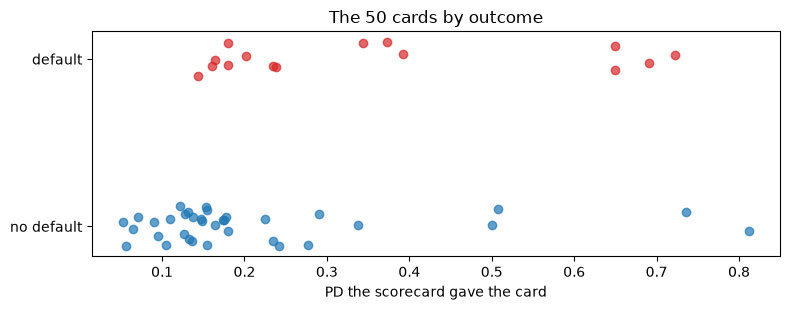

In [3]:
# The 50 cards by outcome: the PD the scorecard gave each one, with a seeded jitter on the vertical axis
print("cards:", len(y), "| defaults:", int(y.sum()), "| default rate:", round(float(y.mean()), 3))
print("mean PD of the scorecard:", round(float(pd_hat.mean()), 4))
print("defaults the PDs expect:", round(float(pd_hat.sum()), 1))

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(8, 3.2))
for outcome, colour in ((0, "tab:blue"), (1, "tab:red")):
    values = pd_hat[y == outcome]
    ax.scatter(values, outcome + rng.uniform(-0.12, 0.12, len(values)), color=colour, alpha=0.7)
ax.set_yticks([0, 1])
ax.set_yticklabels(["no default", "default"])
ax.set_xlabel("PD the scorecard gave the card")
ax.set_title("The 50 cards by outcome")
fig.tight_layout()
plt.show()

Fifteen of the 50 cards defaulted, a rate of 0.3, while the scorecard expected 12.7 defaults from a mean PD of 0.2534. In the figure the red points (defaulters) lean to the right of the blue ones, but the two clouds overlap a great deal: a few non-defaulters carry high PDs and some defaulters carry low ones. The figure shows the ranking as a tendency; it cannot say how strong that tendency is or whether it would survive another 50 cards, and that is what the AUC puts a number on.

### Step 2: the AUC, a test of ranking

The area under the ROC curve is the probability that a defaulter drawn at random received a higher PD than a non-defaulter drawn at random, counting ties as one half (Hanley and McNeil, 1982):

$$\mathrm{AUC} = P(\hat p_{\text{default}} > \hat p_{\text{non-default}}) + \tfrac12\, P(\hat p_{\text{default}} = \hat p_{\text{non-default}})$$

An AUC of 0.5 ranks no better than chance and 1 ranks perfectly. The engine's `disc_auc` returns it with a standard error and a 95% interval (the ECB's variance formula, ECB 2019, Annex 1, section 3.1). The cell below builds the packaged policy, calls the test and prints the pieces of the `TestResult` that matter.

In [4]:
# One call, one TestResult: the AUC of the scorecard on the 50 cards, under the packaged policy
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
policy = default_policy()
auc = disc_auc(pd_hat, y, policy=policy, model_id="P1-scorecard", segment="portfolio")
low, high = auc.extras["ci95_low"], auc.extras["ci95_high"]
print("AUC:", round(auc.metric, 4), "| Gini:", round(auc.extras["gini"], 4))
print("standard error:", round(auc.extras["se"], 4), "| 95% interval:", round(low, 3), "to", round(high, 3))
print("light:", LIGHT[auc.light.value])

AUC: 0.7752 | Gini: 0.5505
standard error: 0.0658 | 95% interval: 0.646 to 0.904
light: not evaluated


The AUC is 0.7752 (a Gini of 0.5505), and its standard error of 0.0658 gives an interval from 0.646 to 0.904. The ranking is clearly better than chance, since the whole interval sits above 0.5, but the interval is wide: the true AUC of this scorecard could be anywhere from mediocre to very good. The light is `not evaluated` because the default policy sets no threshold for the AUC; the number is a measurement, not a verdict.

### Step 3: the Jeffreys test, a test of the level

The AUC says nothing about whether the PDs are the right size. The Jeffreys test asks it for a whole portfolio. Its null hypothesis is that the applied PD is greater than or equal to the true PD, and it rejects when the observed defaults are too many for that. With $D$ defaults among $N$ obligors and an applied PD, the one-sided p-value is a Beta distribution function with Jeffreys' prior (Brown, Cai and DasGupta, 2001; ECB 2019, section 2.5.3.1):

$$p = F_{\mathrm{Beta}(D + 1/2,\; N - D + 1/2)}(\mathrm{PD})$$

A small p means more defaults than the PD allows: the model understates the risk. The next cell calls `pd_jeffreys` with the number of cards, the number of defaults and the mean PD.

In [5]:
# The Jeffreys test on the portfolio of 50 cards: the cards, the defaults and the mean PD the scorecard applied
n_cards, n_defaults, mean_pd = len(y), int(y.sum()), float(pd_hat.mean())
args = dict(n=n_cards, d=n_defaults, pd=mean_pd)
jeffreys = pd_jeffreys(**args, policy=policy, model_id="P1-scorecard", segment="portfolio")
print("inputs: cards", n_cards, "| defaults", n_defaults)
print("applied PD", round(mean_pd, 4))
print("p-value:", round(jeffreys.p_value, 4), "| light:", LIGHT[jeffreys.light.value])
print("amber / red cut points:", jeffreys.alpha_amber, "/", jeffreys.alpha_red)

inputs: cards 50 | defaults 15
applied PD 0.2534
p-value: 0.2211 | light: green
amber / red cut points: 0.05 / 0.01


The p-value is 0.2211 and the light is green: the 15 defaults are not too many for a PD of 0.2534, and the test does not object. The result also records the two cut points of the policy, 0.05 for amber and 0.01 for red. To see what the number is, the next cell evaluates the Beta distribution of the equation directly with SciPy, draws it, and shades the area to the left of the applied PD; that area is the p-value. This is the one comparison of the engine with an independent implementation in this notebook.

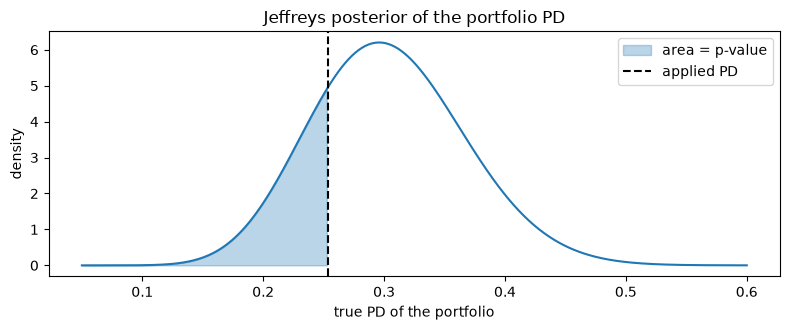

SciPy: 0.22107632 | engine: 0.22107632
equal: True


In [6]:
# The same p-value from SciPy's Beta distribution, drawn as the area to the left of the applied PD
posterior = stats.beta(n_defaults + 0.5, n_cards - n_defaults + 0.5)
grid = np.linspace(0.05, 0.6, 400)
density = posterior.pdf(grid)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(grid, density, color="tab:blue")
ax.fill_between(grid, density, where=grid <= mean_pd, color="tab:blue", alpha=0.3, label="area = p-value")
ax.axvline(mean_pd, color="black", linestyle="--", label="applied PD")
ax.set_xlabel("true PD of the portfolio")
ax.set_ylabel("density")
ax.set_title("Jeffreys posterior of the portfolio PD")
ax.legend()
fig.tight_layout()
plt.show()
print("SciPy:", round(float(posterior.cdf(mean_pd)), 8), "| engine:", round(jeffreys.p_value, 8))
print("equal:", bool(np.isclose(posterior.cdf(mean_pd), jeffreys.p_value)))

The curve is the Beta distribution of the portfolio PD that 15 defaults among 50 cards support, and the dashed line is the PD the scorecard applied. The shaded area to its left is 0.2211, identical to the engine's p-value at eight decimals. The curve is wide, spread from about 0.12 to 0.5, which is the picture of how little 50 cards say about the true PD; it does not show whether the scorecard's PD is right, only that this sample cannot rule it out. A narrow curve would need many more cards.

### Step 4: how many defaults would it take?

Green is the absence of evidence against the PD, so its worth depends on how much evidence the sample could have produced. The engine's `critical_default_count` gives the smallest number of defaults at which a binomial level test at the 95% confidence level rejects the applied PD. The next cell asks it for the 50 cards and for the 9,000 committed holdout cards, and states how far above the expected defaults each sample must go.

In [7]:
# The defaults a 95% level test needs before it objects: 50 cards against the 9,000 committed holdout cards
committed = {
    row["test_id"]: row
    for row in holdout["tests"]
    if row["model_id"] == "P1-scorecard" and row["segment"] == "portfolio"
}
applied_9000 = committed["pd.jeffreys"]["extras"]["pd_applied"]
sizes = {"50 cards": (n_cards, mean_pd), "9,000 cards": (holdout["outputs"]["n"], applied_9000)}
expected = [round(n * p, 1) for n, p in sizes.values()]
needs = [critical_default_count(n, p, q=0.95) for n, p in sizes.values()]
columns = {"defaults the PDs expect": expected, "defaults at which the test objects": needs}
table = pd.DataFrame(columns, index=list(sizes))
table["excess over expected"] = [round(k / e - 1, 3) for k, e in zip(needs, expected)]
table

,defaults the PDs expect,defaults at which the test objects,excess over expected
50 cards,12.7,19,0.496
"9,000 cards",1971.6,2037,0.033


On 50 cards the test objects only from 19 defaults, against 12.7 expected: it needs an excess of about 50 percent before it says a word. On 9,000 cards it objects from 2,037 defaults against 1,971.6 expected, an excess of 3.3 percent. A green light therefore means very different things at the two sizes: on 9,000 cards it rules out a PD that is a few percent too low, and on 50 cards it rules out only a PD that is wrong by half. The table says nothing about whether the scorecard is calibrated; it measures the sensitivity of the test.

### Step 5: the Brier score, a measure of the forecast

The Brier score is the mean squared error of the PD as a forecast of the 0/1 outcome, $\mathrm{BS} = \frac1N \sum_i (\hat p_i - y_i)^2$ (Brier, 1950). Murphy (1973) splits it into reliability (how far the PDs are from the observed rates), resolution (how well they separate) and the uncertainty of the outcome itself, $\mathrm{BS} = \mathrm{REL} - \mathrm{RES} + \mathrm{UNC}$. The identity is exact only when the PDs are constant inside each bin, and the engine records whether it held in `decomposition_exact`. The next cell calls `pd_brier` and prints the parts.

In [8]:
# The Brier score of the 50 cards and the three parts the engine splits it into
brier = pd_brier(y, pd_hat, policy=policy, model_id="P1-scorecard", segment="portfolio")
parts = {
    "reliability": "reliability",
    "resolution": "resolution",
    "uncertainty": "uncertainty",
    "skill against the base rate": "brier_skill",
}
values = [round(brier.extras[key], 4) for key in parts.values()]
table = pd.DataFrame({"part": list(parts), "value": values})
print("Brier:", round(brier.metric, 4), "| light:", LIGHT[brier.light.value])
print("decomposition exact:", brier.extras["decomposition_exact"])
table

Brier: 0.1897 | light: not evaluated
decomposition exact: False


,part,value
0,reliability,0.0319
1,resolution,0.0580
2,uncertainty,0.2100
3,skill against the base rate,0.0967


The Brier score is 0.1897, to be read against the 0.2100 of a forecaster that always gives the base rate: the skill is 0.0967, so the scorecard improves the forecast by about a tenth. The parts do not add up exactly here (0.0319 minus 0.0580 plus 0.2100 is 0.1839, not 0.1897), and `decomposition exact` is False, because the PDs are continuous; the three parts are indicators and not an identity on this sample. Like the AUC, the Brier score carries no light under the default policy.

### Step 6: how much does a smaller slice move the answer?

A validator rarely gets to choose the size of the sample. To feel the noise, the next cell draws 300 half-samples of 25 cards from the 50 (a seeded draw), runs the AUC and the Jeffreys test on each, and compares the distributions with the full-sample and the 9,000-card values. The half-samples overlap, so they are not independent draws from the population; they show how much a 25-card slice moves a result, not the true sampling error.

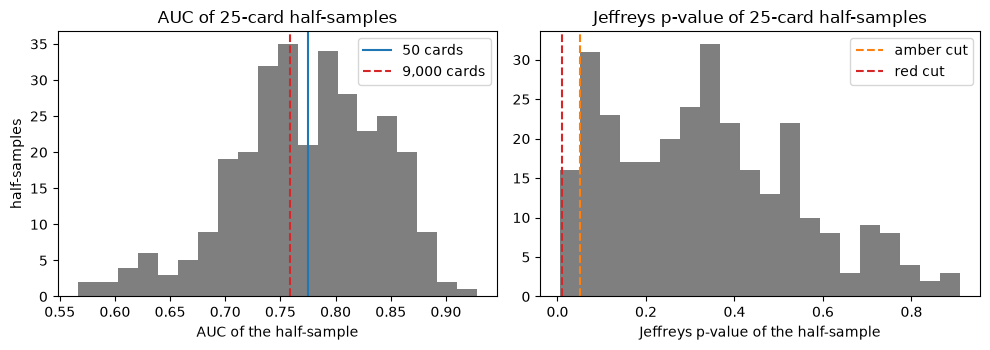

half-samples with both outcomes: 300
share with p below 0.05: 0.05
AUC 5% and 95% of the half-samples: [0.65  0.868]


In [9]:
# Draw 300 half-samples of 25 cards from the same 50 and run two engine tests on each (a seeded draw)
rng = np.random.default_rng(7)
auc_draws, p_draws = [], []
for _ in range(300):
    pick = rng.choice(len(y), size=25, replace=False)
    y_pick, pd_pick = y[pick], pd_hat[pick]
    if 0 < y_pick.sum() < len(pick):
        auc_draws.append(disc_auc(pd_pick, y_pick, policy=policy).metric)
        p_draws.append(pd_jeffreys(n=25, d=int(y_pick.sum()), pd=float(pd_pick.mean()), policy=policy).p_value)

auc_all = committed["disc.auc"]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.hist(auc_draws, bins=20, color="tab:gray")
left.axvline(auc.metric, color="tab:blue", label="50 cards")
left.axvline(auc_all["metric"], color="tab:red", linestyle="--", label="9,000 cards")
left.set(xlabel="AUC of the half-sample", ylabel="half-samples", title="AUC of 25-card half-samples")
left.legend()
right.hist(p_draws, bins=20, color="tab:gray")
right.axvline(0.05, color="tab:orange", linestyle="--", label="amber cut")
right.axvline(0.01, color="tab:red", linestyle="--", label="red cut")
right.set(xlabel="Jeffreys p-value of the half-sample", title="Jeffreys p-value of 25-card half-samples")
right.legend()
fig.tight_layout()
plt.show()
print("half-samples with both outcomes:", len(auc_draws))
print("share with p below 0.05:", round(float(np.mean(np.array(p_draws) < 0.05)), 3))
print("AUC 5% and 95% of the half-samples:", np.percentile(auc_draws, [5, 95]).round(3))

The left panel spreads the AUC of the half-samples: 90 percent of them fall between 0.65 and 0.868, so a 25-card slice can show a mediocre ranking or a very good one from the same data. The blue line (the 50 cards) and the dashed red line (the 9,000 committed cards) sit in the middle of that spread. In the right panel only 5 percent of the Jeffreys p-values fall below the amber cut of 0.05, which is about what a test at that level should flag when the PD is right; the 9,000-card result agrees that it is. The figure shows noise, not bias, and it says nothing about how a wrong PD would look.

### Step 7: the same tests on the 9,000 committed cards

The holdout artifact commits these tests for the whole holdout. The next cell puts the 50-card results beside the committed rows, with the engine version that baked the artifact next to the installed one, as notebook 01 prescribes.

In [10]:
# The results of the 50 cards beside the committed rows of the same tests on the 9,000 holdout cards
jef_all = committed["pd.jeffreys"]
brier_all = committed["pd.brier"]
width_all = auc_all["extras"]["ci95_high"] - auc_all["extras"]["ci95_low"]
width_50 = auc.extras["ci95_high"] - auc.extras["ci95_low"]
numbers_50 = [auc.metric, width_50, jeffreys.p_value, brier.metric]
numbers_9000 = [auc_all["metric"], width_all, jef_all["p_value"], brier_all["metric"]]
table = pd.DataFrame({
    "measure": ["AUC", "width of the 95% interval of the AUC", "Jeffreys p-value", "Brier score"],
    "50 cards": [round(v, 4) for v in numbers_50],
    "9,000 cards": [round(v, 4) for v in numbers_9000],
})
baked_with = holdout["provenance"]["riskvalidation_version"]
print("baked with riskvalidation", baked_with, "| installed:", md.version("riskvalidation"))
table

baked with riskvalidation 1.0.1 | installed: 1.0.1


,measure,50 cards,"9,000 cards"
0,AUC,0.7752,0.7587
1,width of the 95% interval of the AUC,0.2578,0.0253
2,Jeffreys p-value,0.2211,0.3095
3,Brier score,0.1897,0.1393


The point estimates are close: an AUC of 0.7752 on 50 cards and 0.7587 on 9,000, and a Jeffreys p-value of 0.2211 against 0.3095, both green. The uncertainty is not close: the 95% interval of the AUC is 0.2578 wide on 50 cards and 0.0253 wide on 9,000, ten times narrower. The Brier score is worse on the small sample (0.1897 against 0.1393 on 9,000 cards, where lower is better), a reminder that a small sample's score is itself noisy. The versions match, so the committed numbers come from the engine installed here.

## Results

**Answer:** On the 50 cards the scorecard ranks well, with an AUC of 0.7752 and a 95% interval from 0.646 to 0.904, against 0.7587 on the 9,000 committed cards. Its level is not rejected, a Jeffreys p-value of 0.2211 and a green light, but a green light from 50 cards is weak evidence: the level test objects only from 19 defaults against the 12.7 expected, while on 9,000 cards it objects from 2,037 against 1,971.6.

- **Ranking.** The ranking is real and imprecise. Half-samples of 25 cards put the AUC anywhere between 0.65 and 0.868, so read the interval before the point estimate.
- **Level.** A green light is the absence of evidence against the PD, not proof that the PD is right; the amount of evidence a sample can give is the number of defaults it holds.
- **Forecast.** The Brier score of 0.1897 has no light. A validator reads it against the base-rate score of 0.2100, which gives a skill of 0.0967.
- **What a `TestResult` adds** to a bare number: the null hypothesis, the direction of the alternative, the policy that coloured it, the sample sizes, a hash of the inputs and the source that defines the test.

What this notebook does not show: how the policy produced the colours (notebook 03), what happens when many tests run on one sample (notebook 04) or how the scorecard was built (topic 02).

## Summary

- One call returns one `TestResult`: the statistic or metric, the p-value, the null hypothesis, the policy label and light, the sample sizes, an inputs hash and the reference.
- The AUC measures ranking, the Jeffreys test the level of the PDs and the Brier score the forecast; a model can rank well and still be mis-sized, so a validator runs all three.
- The same tests on 50 and on 9,000 cards give close point estimates and very different uncertainty: the interval of the AUC is ten times narrower on 9,000.
- The defaults a level test needs before it objects are the measure of its power: 19 on 50 cards, 2,037 on 9,000.

**What to try next.** Change the slice: take the first 25 cards, then all 50, and watch the AUC interval and the Jeffreys p-value move. Then read `docs/guides/03_read-a-validation-report.md` and continue with notebook 03.

## References

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Annex 1 (section 3.1) and section 2.5.3.1. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hanley, J. A. and McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Brier, G. W. (1950), Monthly Weather Review 78(1), doi 10.1175/1520-0493(1950)078<0001:VOFEIT>2.0.CO;2, and Murphy, A. H. (1973), Journal of Applied Meteorology 12(4), as cited by the engine's `pd.brier` entry.
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients